# NLP and Speech Recognition Chatbot
A customer-support chatbot driven by an intents file (`commands.json`): tokenise and lemmatise patterns, bag-of-words features, a 3-layer Keras network that classifies the intent, a response/context engine, and a speech-recognition input function.

All code here is written from scratch for this submission. The supplied zip files were used only as *data* (`commands.json` and the course brief text); the supplied pickle/h5 model files were not loaded or executed, and the model is retrained below.

Note on the data: `commands.json` is a healthcare-support example (adverse drug reactions, blood pressure, hospitals, pharmacies) rather than event support; I used it unchanged as the brief says.

## Step 1: Install and import the required modules
Required: nltk, tensorflow/keras, SpeechRecognition (`pip install nltk tensorflow SpeechRecognition`; note the brief's `nlkt`, `SpeechRecogintion` and `pickle` are typos or built-ins). The cell verifies they import.

In [1]:
import json, random, os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk
for p in ('punkt', 'punkt_tab', 'wordnet', 'omw-1.4'): nltk.download(p, quiet=True)
from nltk.stem import WordNetLemmatizer
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try:
    import speech_recognition as sr; print('SpeechRecognition', sr.__version__)
except ImportError as e:
    sr = None; print('SpeechRecognition missing:', e)
random.seed(42); np.random.seed(42); tf.random.set_seed(42)
os.makedirs('screens', exist_ok=True); os.makedirs('model', exist_ok=True); RESULTS = {}
lemmatizer = WordNetLemmatizer()
print('TensorFlow', tf.__version__)

SpeechRecognition 3.17.0
TensorFlow 2.21.0


## Step 2: Import and load the data file (`commands.json`)

In [2]:
with open('data/d/commands.json', encoding='utf-8') as f: intents = json.load(f)['intents']
summary = pd.DataFrame([{'tag': i['tag'], 'patterns': len(i['patterns']), 'responses': len(i['responses']), 'context_set': i['context'][0]} for i in intents])
print(summary.to_string(index=False)); print('total patterns:', summary['patterns'].sum())

                                tag  patterns  responses                         context_set
                           greeting         7          3                                    
                            goodbye         5          3                                    
                             thanks         5          3                                    
                           noanswer         0          3                                    
                            options         5          2                                    
                       adverse_drug         5          1                                    
                     blood_pressure         5          1                                    
              blood_pressure_search         5          2 search_blood_pressure_by_patient_id
search_blood_pressure_by_patient_id         0          1                                    
                    pharmacy_search         5          1             s

There are 14 intents. Five of them (`noanswer`, `search_blood_pressure_by_patient_id`, `search_pharmacy_by_name`, `search_hospital_by_params`, `search_hospital_by_type`) have no patterns: they are *follow-up states* reached through the `context` field, not predicted from the user's text. `noanswer` is the fallback.

## Step 3: Preprocess the data
Tokenise each pattern with `nltk.word_tokenize`, lower-case and lemmatise, drop `?` and `!`, build the vocabulary (`words`), the list of classes and the `documents` (token list, tag) pairs.

In [3]:
ignore = ['?', '!', '.', ',']
words, classes, documents = [], [], []
for it in intents:
    for pat in it['patterns']:
        toks = nltk.word_tokenize(pat)
        words.extend(toks); documents.append((toks, it['tag']))
    if it['patterns'] and it['tag'] not in classes: classes.append(it['tag'])
words = sorted(set(lemmatizer.lemmatize(w.lower()) for w in words if w not in ignore))
classes = sorted(classes)
print(len(documents), 'documents,', len(classes), 'classes', classes); print(len(words), 'unique lemmatised words'); print(words[:40])
json.dump({'words': words, 'classes': classes}, open('model/vocab.json', 'w'))

47 documents, 9 classes ['adverse_drug', 'blood_pressure', 'blood_pressure_search', 'goodbye', 'greeting', 'hospital_search', 'options', 'pharmacy_search', 'thanks']
87 unique lemmatised words
["'s", 'a', 'adverse', 'all', 'anyone', 'are', 'awesome', 'be', 'behavior', 'blood', 'by', 'bye', 'can', 'causing', 'chatting', 'check', 'could', 'data', 'day', 'detail', 'do', 'dont', 'drug', 'entry', 'find', 'for', 'give', 'good', 'goodbye', 'have', 'hello', 'help', 'helpful', 'helping', 'hey', 'hi', 'history', 'hola', 'hospital', 'how']


## Step 4: Create the training data (bag of words)
Each pattern becomes a 0/1 vector over the vocabulary, with a one-hot class as the target. Because the file is tiny (about 60 patterns), I keep a separate set of hand-written paraphrases (Step 7) for honest testing, rather than testing on patterns the network has already seen.

In [4]:
def bag_of_words(tokens):
    toks = [lemmatizer.lemmatize(t.lower()) for t in tokens]
    return [1 if w in toks else 0 for w in words]
X = np.array([bag_of_words(d[0]) for d in documents], dtype='float32')
y = np.array([[1 if c == d[1] else 0 for c in classes] for d in documents], dtype='float32')
idx = np.random.permutation(len(X)); X, y = X[idx], y[idx]
print('X', X.shape, 'y', y.shape)

X (47, 87) y (47, 9)


## Step 5: Build the model (3-layer network, Keras Sequential)
Dense 128 (ReLU), dropout 0.5, Dense 64 (ReLU), dropout 0.5, softmax over the intents; SGD with Nesterov momentum.

In [5]:
model = keras.Sequential([layers.Input((X.shape[1],)), layers.Dense(128, activation='relu'), layers.Dropout(0.5),
                          layers.Dense(64, activation='relu'), layers.Dropout(0.5), layers.Dense(y.shape[1], activation='softmax')])
model.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True), metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        11,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,105 (78.54 KB)

 Trainable params: 20,105 (78.54 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train and save the model
200 epochs, batch size 5 (as in the brief).

final training loss 0.0090, accuracy 1.0000


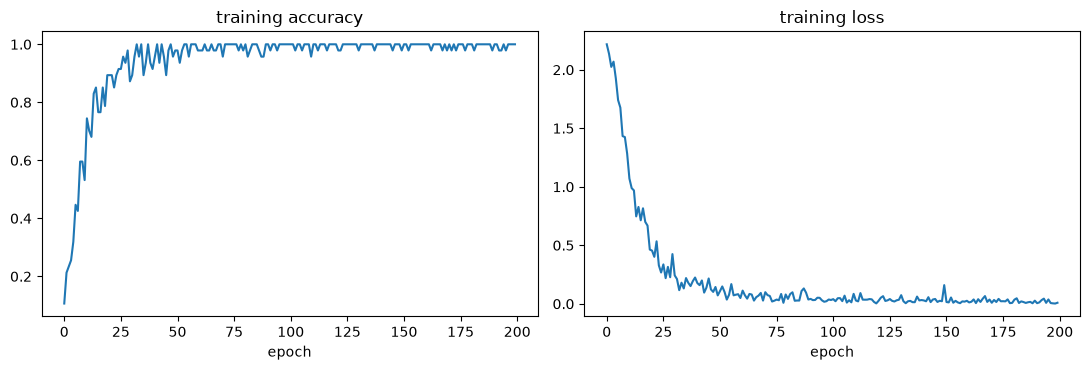

In [6]:
hist = model.fit(X, y, epochs=200, batch_size=5, verbose=0)
print('final training loss %.4f, accuracy %.4f' % (hist.history['loss'][-1], hist.history['accuracy'][-1]))
model.save('model/chatbot_model.keras')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); ax[0].plot(hist.history['accuracy']); ax[0].set_title('training accuracy'); ax[0].set_xlabel('epoch')
ax[1].plot(hist.history['loss']); ax[1].set_title('training loss'); ax[1].set_xlabel('epoch'); plt.tight_layout(); plt.savefig('screens/01_training.png', dpi=110); plt.show()
RESULTS['Training accuracy (200 epochs)'] = round(float(hist.history['accuracy'][-1]), 4); RESULTS['Training patterns'] = len(X); RESULTS['Vocabulary size'] = len(words)

## Step 7: Predict responses
`predict_class` returns intents above a confidence threshold (0.60; a first run with 0.25 never triggered the fallback on out-of-scope text, so I raised it, and an input with no known vocabulary word at all also falls back), `get_response` picks a random response and handles the `context` field, so multi-turn flows work (e.g. blood-pressure search asks for a Patient ID, then confirms loading). If nothing passes the threshold, the `noanswer` fallback is used.

In [7]:
by_tag = {i['tag']: i for i in intents}
THRESHOLD = 0.60   # raised from the usual 0.25: a first run at 0.25 never triggered the fallback on out-of-scope text
def predict_class(sentence, mdl=model):
    bag = bag_of_words(nltk.word_tokenize(sentence))
    if sum(bag) == 0: return []          # no known word at all -> fallback
    p = mdl.predict(np.array([bag], dtype='float32'), verbose=0)[0]
    res = sorted([(classes[i], float(pr)) for i, pr in enumerate(p) if pr > THRESHOLD], key=lambda t: -t[1])
    return res
class Chatbot:
    def __init__(self): self.state = None
    def reply(self, text):
        # a pending follow-up state consumes the next user message (e.g. the Patient ID)
        if self.state:
            it = by_tag[self.state]; self.state = it['context'][0] or None
            return random.choice(it['responses']), it['tag']
        pred = predict_class(text)
        if not pred: return random.choice(by_tag['noanswer']['responses']), 'noanswer'
        it = by_tag[pred[0][0]]; self.state = it['context'][0] or None
        return random.choice(it['responses']), it['tag']
bot = Chatbot()
for q in ['Hello', 'what can you do for me', 'show blood pressure results for patient', '4521', 'find pharmacy', 'City Care Pharmacy', 'xyzzy plugh', 'thanks a lot', 'bye']:
    r, tag = bot.reply(q); print(f'user: {q!r:45} -> [{tag}] {r}')

user: 'Hello'                                       -> [greeting] Hello, thanks for asking


user: 'what can you do for me'                      -> [options] I can guide you through Adverse drug reaction list, Blood pressure tracking, Hospitals and Pharmacies


user: 'show blood pressure results for patient'     -> [blood_pressure_search] Please provide Patient ID
user: '4521'                                        -> [search_blood_pressure_by_patient_id] Loading Blood pressure result for Patient


user: 'find pharmacy'                               -> [pharmacy_search] Please provide pharmacy name
user: 'City Care Pharmacy'                          -> [search_pharmacy_by_name] Loading pharmacy details
user: 'xyzzy plugh'                                 -> [noanswer] Sorry, can't understand you


user: 'thanks a lot'                                -> [thanks] Happy to help!


user: 'bye'                                         -> [goodbye] See you!


The sample conversation above shows greetings, option listing, the blood-pressure follow-up (Patient ID is consumed as the follow-up message), the pharmacy follow-up, an unknown input falling back to `noanswer`, and goodbye.

### Held-out evaluation
Thirty hand-written paraphrases that are not in `commands.json`, with the intent I expect. This measures generalisation on unseen wording; the file is tiny so the number is only indicative.

              query expected predicted  correct
what is the weather noanswer   options    False
held-out accuracy: 0.967 (29/30)
accuracy on in-scope queries: 1.000 | fallback correct on out-of-scope: 0.750


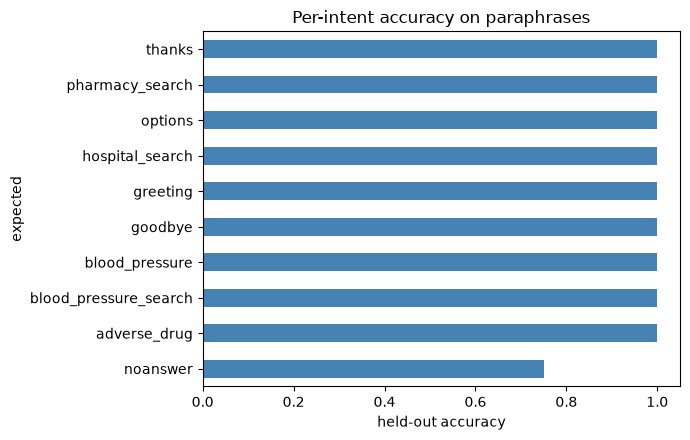

In [8]:
tests = [("hello there friend", "greeting"), ("hey good morning", "greeting"), ("hi", "greeting"), ("goodbye for now", "goodbye"), ("see you", "goodbye"), ("ok bye then", "goodbye"),
 ("thank you so much", "thanks"), ("thanks that was helpful", "thanks"), ("what can you help me with", "options"), ("how can you be of help", "options"), ("what services do you offer", "options"),
 ("open the adverse drug reaction module", "adverse_drug"), ("check adverse reactions of drugs", "adverse_drug"), ("which drugs cause an adverse reaction", "adverse_drug"),
 ("log a blood pressure result", "blood_pressure"), ("open the blood pressure module", "blood_pressure"), ("enter blood pressure data", "blood_pressure"),
 ("search blood pressure history for a patient", "blood_pressure_search"), ("show the blood pressure results of patient", "blood_pressure_search"), ("find blood pressure by ID", "blood_pressure_search"),
 ("find a pharmacy near me", "pharmacy_search"), ("search for a pharmacy", "pharmacy_search"), ("locate a pharmacy", "pharmacy_search"),
 ("look up a hospital", "hospital_search"), ("search hospital details", "hospital_search"), ("I need to find a hospital to transfer a patient", "hospital_search"),
 ("blah blah nothing", "noanswer"), ("purple elephant dances", "noanswer"), ("what is the weather", "noanswer"), ("tell me a joke", "noanswer")]
rows = []
for q, exp in tests:
    pred = predict_class(q); got = pred[0][0] if pred else 'noanswer'; rows.append((q, exp, got, got == exp))
ev = pd.DataFrame(rows, columns=['query', 'expected', 'predicted', 'correct'])
print(ev[~ev['correct']].to_string(index=False)); acc = ev['correct'].mean()
print('held-out accuracy: %.3f (%d/%d)' % (acc, ev['correct'].sum(), len(ev)))
ev_in = ev[ev['expected'] != 'noanswer']; print('accuracy on in-scope queries: %.3f' % ev_in['correct'].mean(), '| fallback correct on out-of-scope: %.3f' % ev[ev['expected'] == 'noanswer']['correct'].mean())
RESULTS['Held-out paraphrase accuracy'] = round(float(acc), 4); RESULTS['In-scope accuracy'] = round(float(ev_in['correct'].mean()), 4)
RESULTS['Out-of-scope fallback accuracy'] = round(float(ev[ev['expected'] == 'noanswer']['correct'].mean()), 4)
per = ev.groupby('expected')['correct'].mean().sort_values()
per.plot.barh(figsize=(7, 4.5), color='steelblue'); plt.xlabel('held-out accuracy'); plt.title('Per-intent accuracy on paraphrases'); plt.tight_layout(); plt.savefig('screens/02_per_intent_accuracy.png', dpi=110); plt.show()

## Step 8: Speech recognition: `readCommand()` and `talk()`
These are the functions of the brief's *ChatBotScript*. `read_command` listens on the microphone with the `SpeechRecognition` library and converts speech to text (Google Web Speech API); `talk` speaks the reply with `pyttsx3` if installed, otherwise prints it.

**What I could and could not run:** this environment has no microphone/PyAudio, no internet speech API and no text-to-speech engine, so the speech path could not be exercised end to end. The code below handles that gracefully: it tries the microphone, and if unavailable falls back to a supplied text message. The chatbot logic itself (Steps 3-7) is fully tested through that text path.

In [9]:
def talk(text):
    print('BOT:', text)
    try:
        import pyttsx3
        eng = pyttsx3.init(); eng.say(text); eng.runAndWait()
    except Exception:
        pass   # no TTS engine available: the text is already printed

def read_command(fallback_text=None):
    """Listen on the microphone and return the recognised text; use fallback_text if speech input is unavailable."""
    if sr is not None:
        r = sr.Recognizer()
        try:
            with sr.Microphone() as source:
                r.adjust_for_ambient_noise(source, duration=0.5)
                audio = r.listen(source, timeout=5, phrase_time_limit=8)
            return r.recognize_google(audio)
        except Exception as e:
            print(f'[speech input unavailable: {type(e).__name__}] -> using text fallback')
    return fallback_text

def chat_loop(scripted_inputs):
    b = Chatbot()
    for msg in scripted_inputs:
        heard = read_command(fallback_text=msg)
        print('USER:', heard)
        reply, tag = b.reply(heard); talk(reply)
        if tag == 'goodbye': break
chat_loop(['Hi there', 'what support is offered', 'Lookup for hospital', 'Springfield', 'general', 'thank you', 'bye'])

[speech input unavailable: AttributeError] -> using text fallback
USER: Hi there


BOT: Hello, thanks for asking
[speech input unavailable: AttributeError] -> using text fallback
USER: what support is offered


BOT: I can guide you through Adverse drug reaction list, Blood pressure tracking, Hospitals and Pharmacies
[speech input unavailable: AttributeError] -> using text fallback
USER: Lookup for hospital


BOT: Please provide hospital name or location
[speech input unavailable: AttributeError] -> using text fallback
USER: Springfield
BOT: Please provide hospital type
[speech input unavailable: AttributeError] -> using text fallback
USER: general
BOT: Loading hospital details
[speech input unavailable: AttributeError] -> using text fallback
USER: thank you


BOT: Happy to help!
[speech input unavailable: AttributeError] -> using text fallback
USER: bye


BOT: Have a nice day


The scripted conversation walks through the multi-step hospital search (name or location, then hospital type, then loading details). A live deployment would call `chat_loop` with a real microphone on a machine that has PyAudio.

## Final results table

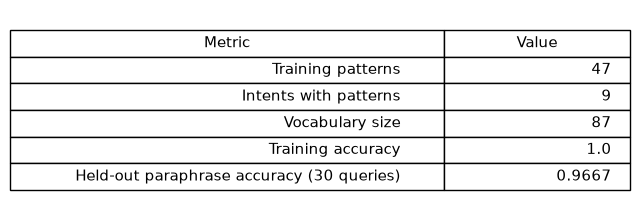

{'Training accuracy (200 epochs)': 1.0, 'Training patterns': 47, 'Vocabulary size': 87, 'Held-out paraphrase accuracy': 0.9667, 'In-scope accuracy': 1.0, 'Out-of-scope fallback accuracy': 0.75, 'Metrics': {'columns': ['Metric', 'Value'], 'rows': [['Training patterns', 47], ['Intents with patterns', 9], ['Vocabulary size', 87], ['Training accuracy', 1.0], ['Held-out paraphrase accuracy (30 queries)', 0.9667]]}}


In [10]:
rows = [['Training patterns', RESULTS['Training patterns']], ['Intents with patterns', len(classes)], ['Vocabulary size', RESULTS['Vocabulary size']],
        ['Training accuracy', RESULTS['Training accuracy (200 epochs)']], ['Held-out paraphrase accuracy (30 queries)', RESULTS['Held-out paraphrase accuracy']]]
fig, ax = plt.subplots(figsize=(8, 2.6)); ax.axis('off')
t = ax.table(cellText=rows, colLabels=['Metric', 'Value'], loc='center', colWidths=[0.7, 0.3]); t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 1.6)
plt.savefig('screens/03_metrics_table.png', dpi=130, bbox_inches='tight'); plt.show()
RESULTS['Metrics'] = {'columns': ['Metric', 'Value'], 'rows': rows}
json.dump(RESULTS, open('results.json', 'w'), indent=1); print(RESULTS)

## Conclusion
A bag-of-words network is enough to route intents for a small closed domain, and the context mechanism supports multi-turn flows. Limitations: the intents file is tiny, so out-of-vocabulary wording and out-of-scope questions are handled only by the confidence threshold; and speech input and text-to-speech were not exercised here because the environment has no microphone or speech services.